# 01 — Synthetic clear-sky generation

Physics forward model: random European sites, pvlib solar position + plane-of-array irradiance, 30-minute steps for one year.

The original lab run wrote 100 CSVs. This public repo keeps one sample at `data/synthetic/sample_site_0.csv`. Regenerate a panel with:

```bash
python src/generate_synthetic.py --n-sites 100
```

Files land in `data/synthetic/generated/` (gitignored). Capacity (`pv_dc_kwp`) is a random label and is **not** used in the irradiance calculation — a known limitation of this pipeline.


# Virtual Power Generator
### This JupyterNotebook will apply pvlib to generate virtual data for training SimpleNN


In [1]:
## Author: Yife,
## Date: 2025.2.1
## Description: This code is used to generate virtual power data for training the model
## Change History: 2.1.2025 First version
## Libraries and versions:

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pvlib


## By applying pvlib and generated virtual location data and solar panel parameters, we generate solar power generation data for a whole year with 30minutes interval

In [3]:
import pandas as pd
import numpy as np
import pvlib
from datetime import datetime, timedelta

def generate_solar_data_utc(n):
    """
    Generate synthetic solar power data using UTC time
    
    Parameters:
        n (int): Number of data samples to generate
    Returns:
        list: List of dictionaries containing generated data samples
    """
    np.random.seed(42)  # Ensure reproducibility
    data_list = []
    
    for _ in range(n):
        # 1. Generate European geographical coordinates
        lat = np.random.uniform(35.0, 70.0)   # Latitude range for Europe
        lon = np.random.uniform(-10.0, 40.0)  # Longitude range for Europe
        
        # 2. Generate UTC start date (within last 5 years)
        start_date = datetime.utcnow() - timedelta(days=np.random.randint(1, 5*365))
        start_date = start_date.replace(hour=0, minute=0, second=0, microsecond=0)
        
        # 3. Generate solar panel angles
        tilt = np.random.uniform(0, 90)       # Tilt angle (0-90 degrees)
        azimuth = np.random.uniform(0, 360)   # Azimuth angle (0-360 degrees)
        
        # 4. Create full-year time series (UTC, 30-min intervals)
        times = pd.date_range(
            start=start_date,
            end=start_date + timedelta(days=365),
            freq='30min',
            inclusive='left',
            tz='UTC'
        )
        
        # 5. Calculate solar position using PVLib
        solar_position = pvlib.solarposition.get_solarposition(
            times,
            lat,
            lon,
            altitude=0,
            pressure=101325,  # Standard atmospheric pressure (Pa)
            temperature=12    # Average temperature (°C)
        )
        
        # 6. Calculate plane-of-array irradiance
        irradiance = pvlib.irradiance.get_total_irradiance(
            surface_tilt=tilt,
            surface_azimuth=azimuth,
            solar_zenith=solar_position['apparent_zenith'],
            solar_azimuth=solar_position['azimuth'],
            dni=1000,  # Direct Normal Irradiance (W/m²)
            ghi=800,   # Global Horizontal Irradiance (W/m²)
            dhi=200,   # Diffuse Horizontal Irradiance (W/m²)
            albedo=0.3 # Surface albedo (ground reflectivity)
        )
        
        # 7. Calculate power generation with system losses
        system_loss = 0.15  # 15% total system losses
        power = irradiance['poa_global'] * (1 - system_loss)
        power = power.resample('30min').mean().tolist()  # Ensure 30-min resolution
        
        # 8. Build data entry
        data_entry = {
            'latitude': round(lat, 4),
            'longitude': round(lon, 4),
            'start_date_utc': start_date.strftime('%Y-%m-%dT%H:%M:%SZ'),
            'tilt': round(tilt, 2),
            'azimuth': round(azimuth, 2),
            'time_series': {
                'timestamps': [ts.isoformat() for ts in times],
                'power': [round(p, 2) for p in power]
            }
        }
        
        data_list.append(data_entry)
    
    return data_list


The above function could be improved by adding randomness into panel power 

In [4]:
# call the function
if __name__ == "__main__":
    sample_data = generate_solar_data_utc(1)  # use src/generate_synthetic.py --n-sites 100 for the full panel ## change the arg into samples you want to generate
    # print(f"Generated {len(sample_data)} samples")
    # print("Sample structure:", list(sample_data[0].keys()))
    # print("First timestamp:", sample_data[0]['time_series']['timestamps'][0])
    # print("First power value:", sample_data[0]['time_series']['power'][0])

/var/folders/t8/v47_v86n5mn1yv6hfbq9k70w0000gn/T/ipykernel_62283/2349991009.py:24: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  start_date = datetime.utcnow() - timedelta(days=np.random.randint(1, 5*365))
/var/folders/t8/v47_v86n5mn1yv6hfbq9k70w0000gn/T/ipykernel_62283/2349991009.py:24: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  start_date = datetime.utcnow() - timedelta(days=np.random.randint(1, 5*365))
/var/folders/t8/v47_v86n5mn1yv6hfbq9k70w0000gn/T/ipykernel_62283/2349991009.py:24: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now

# The next cell code could be potential improvements in the future:

In [5]:
## Potential improvement
# Replace a real time weather model
# weather = pvlib.iotools.get_psm3(
#     latitude=lat,
#     longitude=lon,
#     api_key='YOUR_API_KEY',
#     email='your.email@example.com'
# )
# Generate more reasonal tile angle as a normal distrubtions
# optimal_tilt = lat * 0.9 + 3
# tilt = np.random.normal(optimal_tilt, 10)  # perfect tilt ±10°
# tilt = np.clip(tilt, 0, 90)

# optimal_orientataion = 180  # South-facing panels
# orientataion = np.random.normal(optimal_orientataion, 45)  # ±45°
# orientataion = orientataion % 360
# Add noise to the power data
# noise = np.random.normal(0, 50, len(power))
# power = np.clip(power + noise, 0, None)

## Sample data validation

latitude：69.08°
longitude：1.64°
Install angles：Tilt 70.67°，orientation 71.88°
Length of time series（Expectation:17520 points）：17520


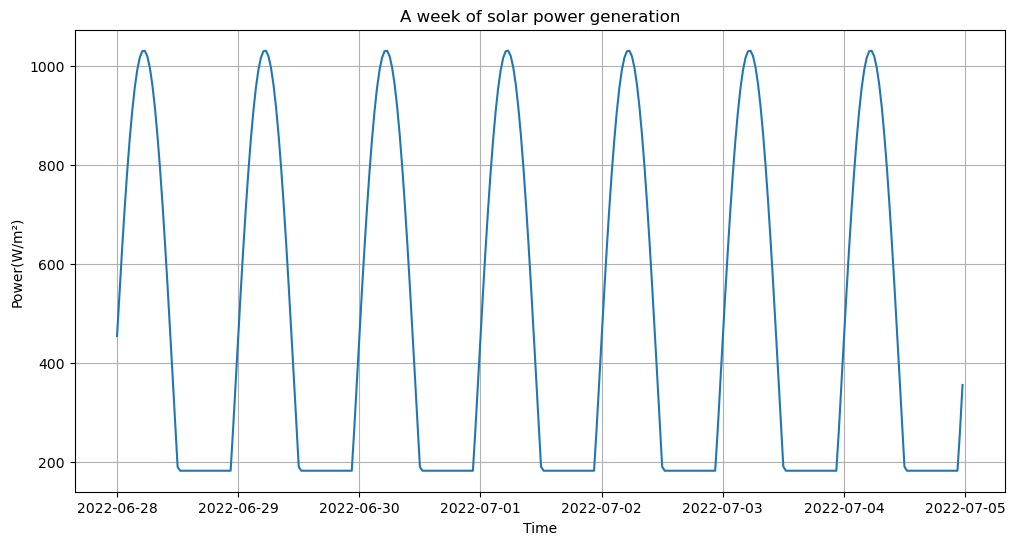

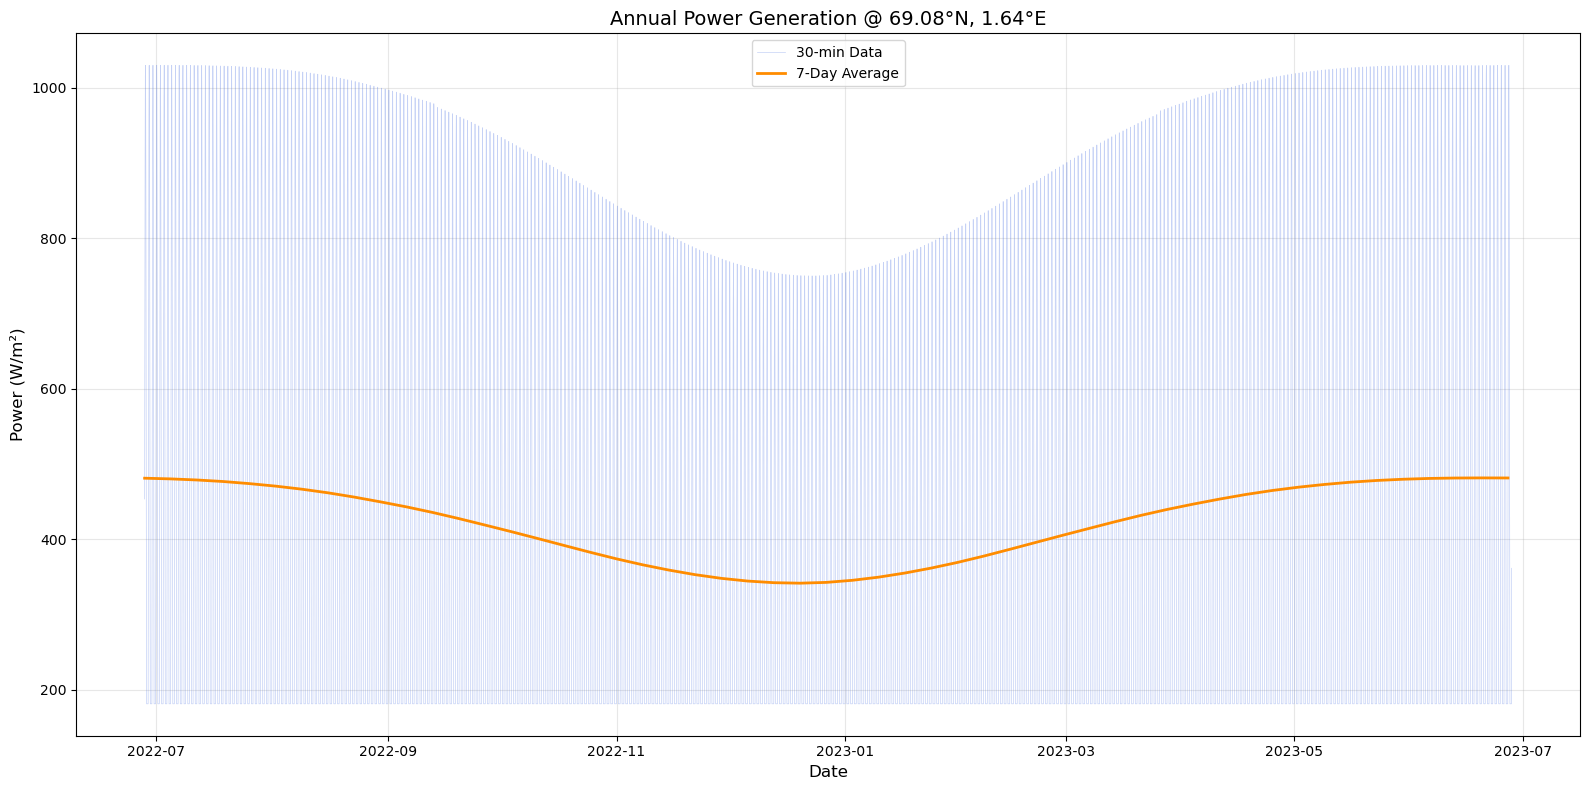

In [6]:
# validation for a single sample
sample = sample_data[5]

print(f"latitude：{sample['latitude']:.2f}°")
print(f"longitude：{sample['longitude']:.2f}°")
print(f"Install angles：Tilt {sample['tilt']}°，orientation {sample['azimuth']}°")
print(f"Length of time series（Expectation:17520 points）：{len(sample['time_series']['power'])}")

# Plot the first week of power data
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
plt.plot(pd.to_datetime(sample['time_series']['timestamps'][:48*7]), 
         sample['time_series']['power'][:48*7])
plt.title('A week of solar power generation')
plt.xlabel('Time')
plt.ylabel('Power(W/m²)')
plt.grid(True)
plt.show()


# plot the annual power generation
def plot_annual_power(sample):
    
    plt.figure(figsize=(16, 8))
    
    # time series transformation
    timestamps = pd.to_datetime(sample['time_series']['timestamps'])
    power = sample['time_series']['power']
    
    # plot dataframes
    df = pd.DataFrame({
        'timestamp': timestamps,
        'power': power
    }).set_index('timestamp')
    
    # main curve: 30-min data
    plt.plot(df.index, df['power'], 
             color='royalblue',
             alpha=0.3,
             linewidth=0.5,
             label='30-min Data')
    
    # auxiliary curve: 7-day average
    df_weekly = df.resample('7D').mean()
    plt.plot(df_weekly.index, df_weekly['power'],
             color='darkorange',
             linewidth=2,
             label='7-Day Average')
    
    # improve the plot
    plt.title(f"Annual Power Generation @ {sample['latitude']:.2f}°N, {sample['longitude']:.2f}°E", fontsize=14)
    plt.xlabel('Date', fontsize=12)
    plt.ylabel('Power (W/m²)', fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.legend()
    
    plt.tight_layout()
    plt.show()

# apply the function
plot_annual_power(sample_data[5])

## In following code, you need to transfer the sample data from Dictionary form into Pandas DataFrame form

In [7]:
sample_data[5]

{'latitude': 69.0814,
 'longitude': 1.6386,
 'start_date_utc': '2022-06-28T00:00:00Z',
 'tilt': 70.67,
 'azimuth': 71.88,
 'time_series': {'timestamps': ['2022-06-28T00:00:00+00:00',
   '2022-06-28T00:30:00+00:00',
   '2022-06-28T01:00:00+00:00',
   '2022-06-28T01:30:00+00:00',
   '2022-06-28T02:00:00+00:00',
   '2022-06-28T02:30:00+00:00',
   '2022-06-28T03:00:00+00:00',
   '2022-06-28T03:30:00+00:00',
   '2022-06-28T04:00:00+00:00',
   '2022-06-28T04:30:00+00:00',
   '2022-06-28T05:00:00+00:00',
   '2022-06-28T05:30:00+00:00',
   '2022-06-28T06:00:00+00:00',
   '2022-06-28T06:30:00+00:00',
   '2022-06-28T07:00:00+00:00',
   '2022-06-28T07:30:00+00:00',
   '2022-06-28T08:00:00+00:00',
   '2022-06-28T08:30:00+00:00',
   '2022-06-28T09:00:00+00:00',
   '2022-06-28T09:30:00+00:00',
   '2022-06-28T10:00:00+00:00',
   '2022-06-28T10:30:00+00:00',
   '2022-06-28T11:00:00+00:00',
   '2022-06-28T11:30:00+00:00',
   '2022-06-28T12:00:00+00:00',
   '2022-06-28T12:30:00+00:00',
   '2022-06-28T13

## Transfer into DataFrame

In [8]:
timestamps = pd.to_datetime(sample['time_series']['timestamps'])
power_values = sample['time_series']['power']

# create a DataFrame
df = pd.DataFrame({
    'timestamp': timestamps,
    'power': power_values
}).set_index('timestamp')

# example
print(df.head())


                            power
timestamp                        
2022-06-28 00:00:00+00:00  453.62
2022-06-28 00:30:00+00:00  543.55
2022-06-28 01:00:00+00:00  629.62
2022-06-28 01:30:00+00:00  710.38
2022-06-28 02:00:00+00:00  784.49


In [9]:
# Save to CSV
import random
df.to_csv('../data/synthetic/generated/sample_data.csv', index_label='timestamp_utc')
# Save each sample data to a separate CSV file
for i, sample in enumerate(sample_data):
    timestamps = pd.to_datetime(sample['time_series']['timestamps'])
    power_values = sample['time_series']['power']
    
    # create a DataFrame
    df = pd.DataFrame({
        'timestamp': timestamps,
        'power': power_values
    }).set_index('timestamp')
    
    # Add site_id and other details to the DataFrame
    df['site_id'] = i
    df['latitude'] = sample['latitude']
    df['longitude'] = sample['longitude']
    df['pv_dc_kwp'] = round(random.uniform(1, 5), 2)  # Assuming 1 kWp for simplicity
    df['pv_array_tilt'] = sample['tilt']
    df['pv_array_a_orientation'] = sample['azimuth']
    df['solar_gen_kwh'] = df['power'] / 1000  # Convert W to kW
    
    # Reorder columns
    df = df[['site_id', 'latitude', 'longitude', 'pv_dc_kwp', 'pv_array_tilt', 'pv_array_a_orientation', 'solar_gen_kwh']]
    
    # Save to CSV
    df.to_csv(f'../data/synthetic/generated/sample_data_site_{i}.csv', index_label='timestamp_utc')

## Save to CSV

In [8]:
# ....
# save the data to a CSV file
